# Section1.2 - Feature Engineering

Generate additional features e.g., quantifying the traffic related to each flow based
on the previous analysis (e.g., avg, min, max, quantiles, etc.)

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('ddos_dataset.csv', dtype={'SimillarHTTP':str}, index_col=0)
df.columns = df.columns.str.strip()

## Feature Creation

In [ ]:
nums = ['Total Length of Bwd Packets',
        'Flow Bytes/s', 
        'Flow IAT Std',
        'Total Fwd Packets',
        'Total Length of Fwd Packets',
        ]
denums = ['Total Length of Fwd Packets',
          'Flow Packets/s',
          'Flow IAT Mean',
          'Total Backward Packets',
          'Total Length of Bwd Packets'
          ]

df[denums] = df[denums].replace(0, 1e-12) # Avoiding Division by 0

cols = nums + denums


df['MultiplicationFactor']  = df['Total Length of Bwd Packets'] / df['Total Length of Fwd Packets']
df['Bytes_per_Packet']      = df['Flow Bytes/s']                / df['Flow Packets/s']
df['IAT_std_on_mean']       = df['Flow IAT Std']                / df['Flow IAT Mean']
df['Fwd_Bwd_Packets_Ratio'] = df['Total Fwd Packets']           / df['Total Backward Packets']
df['Fwd_Bwd_Bytes_Ratio']   = df['Total Length of Fwd Packets'] / df['Total Length of Bwd Packets']



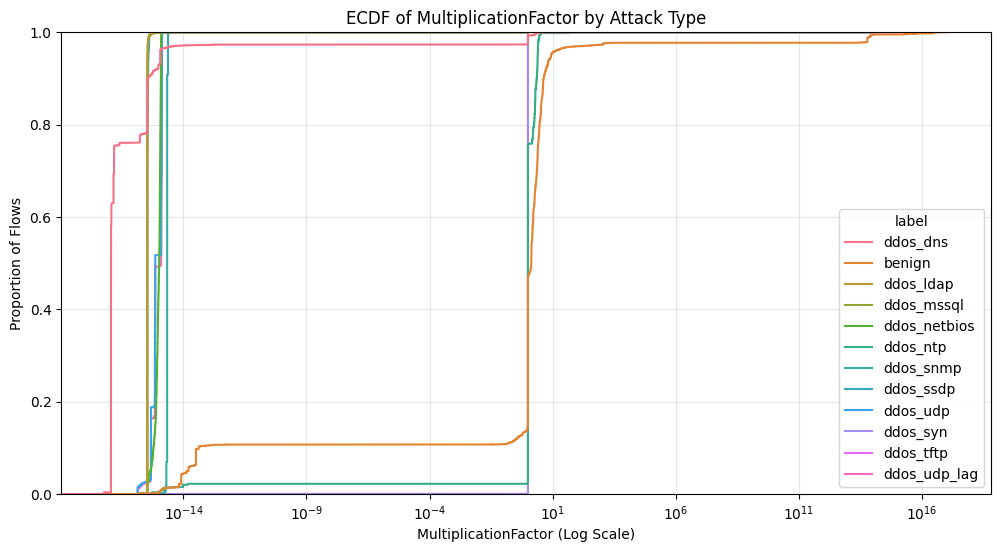

In [ ]:
plt.figure(figsize=(12, 6))


sns.ecdfplot(data=df, x='MultiplicationFactor', hue='label')

plt.title('ECDF of MultiplicationFactor by Attack Type')
plt.xlabel('MultiplicationFactor (Log Scale)')
plt.ylabel('Proportion of Flows')
plt.xscale('log')
plt.grid(True, alpha=0.3)

plt.show()

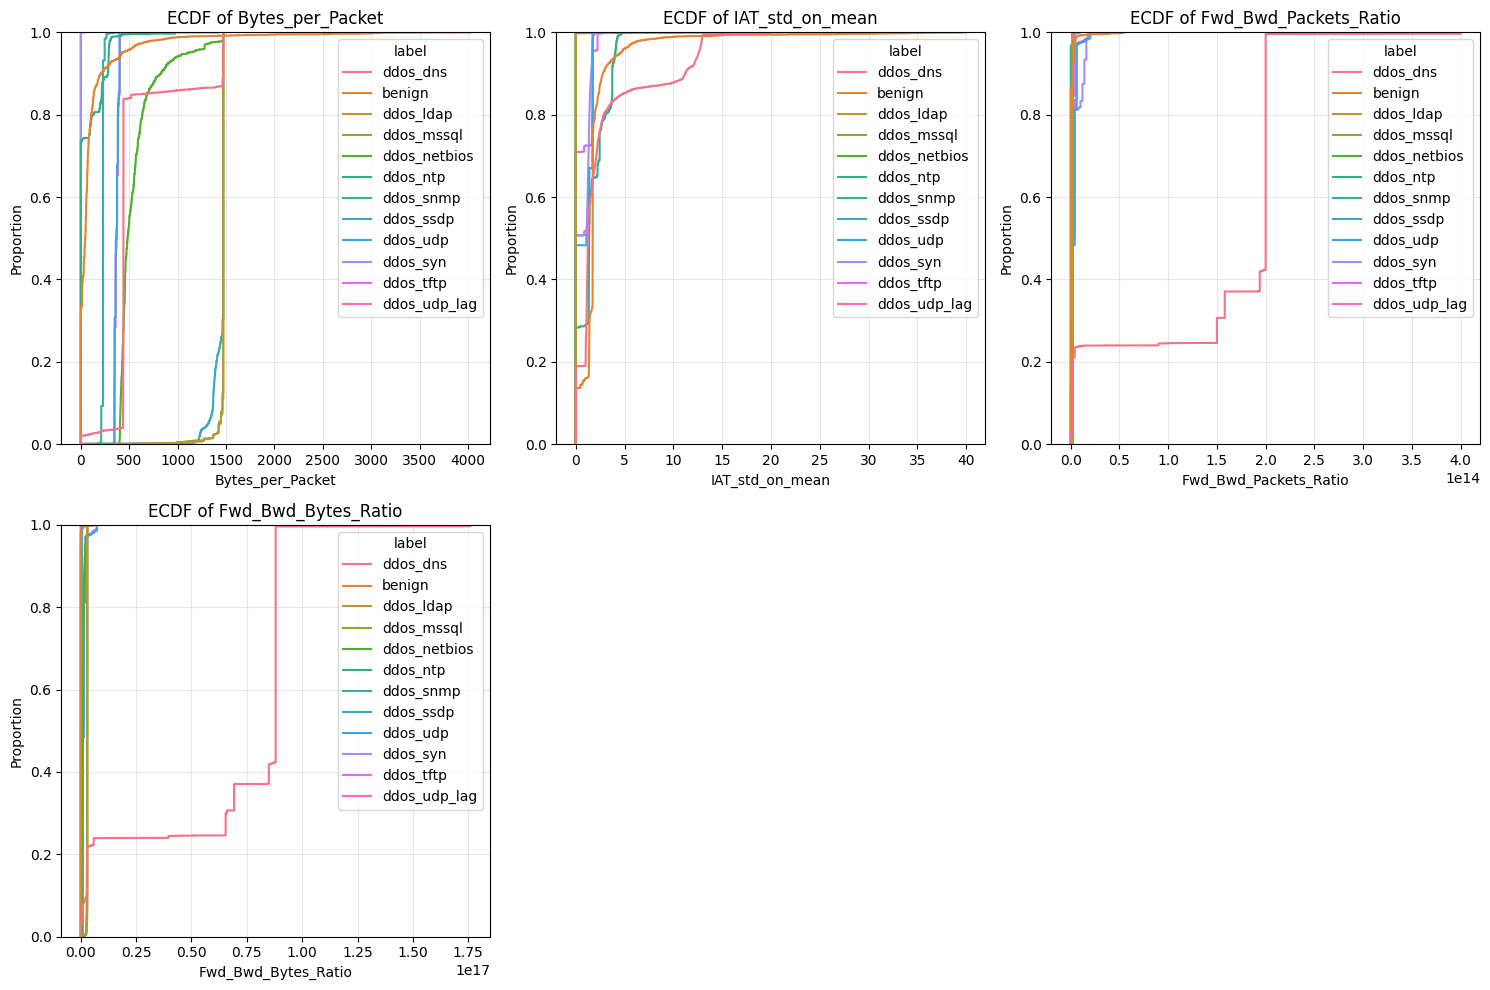

In [25]:
# ECDF of the new ratio features
ratio_features = [
    'Bytes_per_Packet',
    'IAT_std_on_mean',
    'Fwd_Bwd_Packets_Ratio',
    'Fwd_Bwd_Bytes_Ratio'
]

plt.figure(figsize=(15, 10))
for i, col in enumerate(ratio_features):
    plt.subplot(2, 3, i+1)
    
    # Plot ECDF separated by Label
    sns.ecdfplot(data=df, x=col, hue='label')    
    
    plt.title(f'ECDF of {col}')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# Creation of Port Category
def categorize_port(port):
    if port >= 0 and port <= 1023:
        return 0  # Well-known
    elif port >= 1024 and port <= 49151:
        return 1  # Registered
    elif port >= 49152 and port <= 65535:
        return 2  # Ephemeral
    else:
        return -1 # Invalid/Unknown

df['src_port_category'] = df['Source Port'].apply(categorize_port)
df['dst_port_category'] = df['Destination Port'].apply(categorize_port)

In [27]:
# Creation of IP Addr Category
import ipaddress

def is_ip_private(ip_str):
    try:
        ip = ipaddress.ip_address(ip_str)
        return 1 if ip.is_private else 0
    except ValueError:
        return 0  # potential invalid IP

df['private_src_ip'] = df['Source IP'].apply(is_ip_private)
df['private_dst_ip'] = df['Destination IP'].apply(is_ip_private)

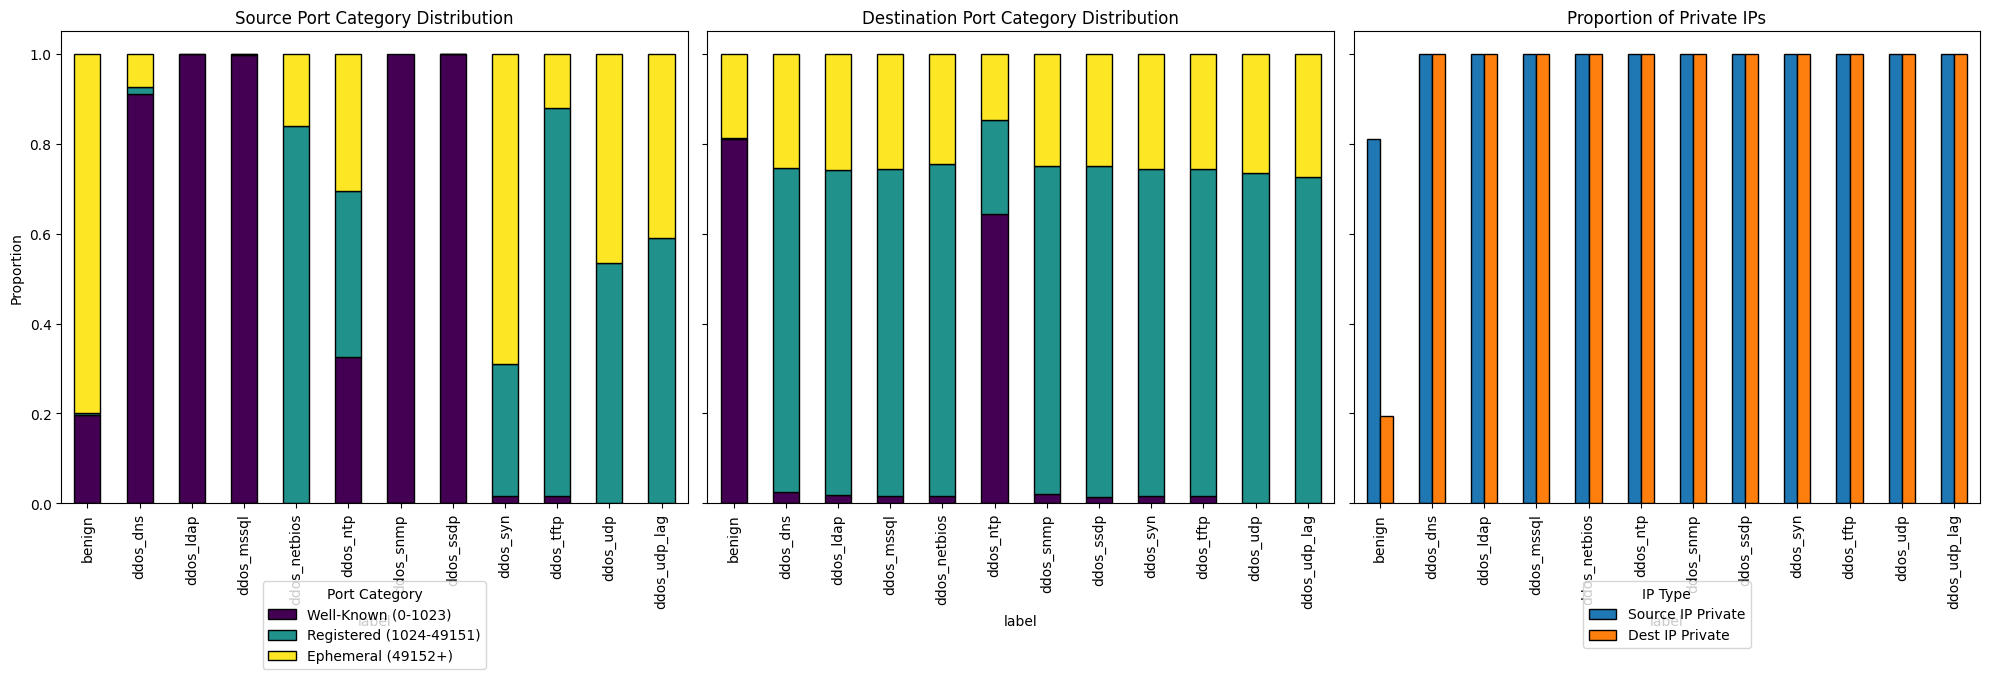

In [ ]:
# crosstab to get counts and normalize='index' to get percentages (0-1)
src_port_dist = pd.crosstab(df['label'], df['src_port_category'], normalize='index')
dst_port_dist = pd.crosstab(df['label'], df['dst_port_category'], normalize='index')

# For Private IPs we just need the mean (since the values are 0 or 1)
# This gives us the % of traffic that is private for each label
ip_dist = df.groupby('label')[['private_src_ip', 'private_dst_ip']].mean()

port_map = {0: 'Well-Known (0-1023)', 1: 'Registered (1024-49151)', 2: 'Ephemeral (49152+)', -1: 'Unknown'}
src_port_dist.rename(columns=port_map, inplace=True)
dst_port_dist.rename(columns=port_map, inplace=True)
ip_dist.rename(columns={'private_src_ip': 'Source IP Private', 'private_dst_ip': 'Dest IP Private'}, inplace=True)

fig, axes = plt.subplots(1, 3, figsize=(20, 7), sharey=True)

# Plot 1: Source Port Distribution
src_port_dist.plot(kind='bar', stacked=True, ax=axes[0], colormap='viridis', edgecolor='black')
axes[0].set_title('Source Port Category Distribution')
axes[0].set_ylabel('Proportion')
axes[0].legend(title='Port Category', bbox_to_anchor=(0.5, -0.15), loc='upper center')

# Plot 2: Destination Port Distribution
dst_port_dist.plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis', edgecolor='black')
axes[1].set_title('Destination Port Category Distribution')
axes[1].get_legend().remove() # Remove legend as it's same as Plot 1

# Plot 3: Private IP Distribution (NOT stacked because Src and Dst are independent properties)
ip_dist.plot(kind='bar', stacked=False, ax=axes[2], color=['#1f77b4', '#ff7f0e'], edgecolor='black')
axes[2].set_title('Proportion of Private IPs')
axes[2].legend(title='IP Type', bbox_to_anchor=(0.5, -0.15), loc='upper center')

plt.tight_layout()
plt.show()

## Feature Transformation

In [29]:
#Feature Transformation of Timestamp
df['Timestamp'] = pd.to_datetime(df['Timestamp']) # from string to datetime format
df['hour'] = df['Timestamp'].dt.hour # from string to datetime format
df['day_of_week'] = df['Timestamp'].dt.dayofweek # extract the day

## Dimensionality Reduction
List `to_be_dropped` for useless variable or variable that needs to be dropped

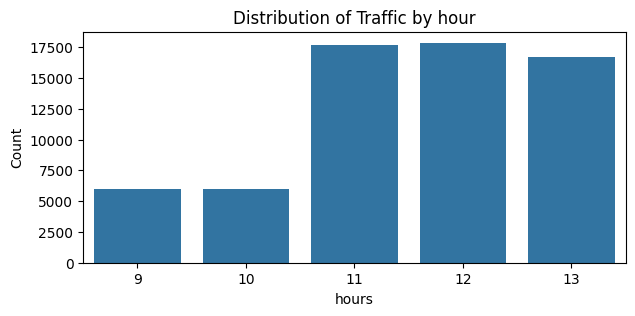

In [ ]:
plt.figure(figsize=(7, 3))

ax = sns.countplot(data=df, x='hour')

plt.title("Distribution of Traffic by hour")
plt.xlabel("hours")
plt.ylabel("Count")
plt.show()

#to_be_dropped += ['hour']

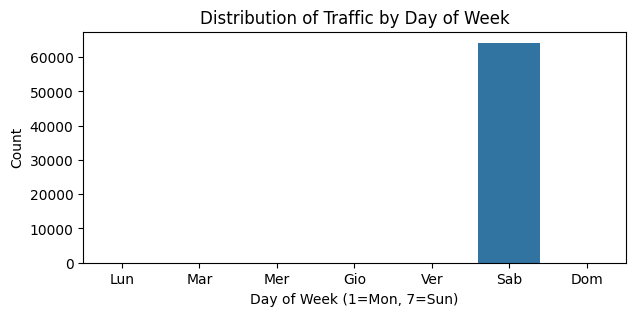

In [ ]:
plt.figure(figsize=(7, 3))

ax = sns.countplot(data=df, x='day_of_week', order=range(0, 7))

ax.set_xticklabels(['Lun', 'Mar', 'Mer', 'Gio', 'Ver', 'Sab', 'Dom'])
plt.title("Distribution of Traffic by Day of Week")
plt.xlabel("Day of Week (1=Mon, 7=Sun)")
plt.ylabel("Count")
plt.show()

#to_be_dropped += ['day_of_week']

In [32]:
# Function definition later used for dimensionality reduction
def get_duplicate_columns(df):
    """
    Analyzes the dataframe for exact duplicates.
    
    Returns:
        duplicate_map (dict): A dictionary where:
            Key   = The column name to KEEP (the first occurrence)
            Value = A list of column names to DROP (the duplicates)
    """
    print(f"Scanning {df.shape[1]} columns for exact duplicates...")
    cols = df.columns.tolist()
    processed_cols = set()
    
    # Dictionary to store { 'Keep_Col': ['Drop_Col1', 'Drop_Col2'] }
    duplicate_map = {}
    
    for i in range(len(cols)):
        col_a = cols[i]
        
        if col_a in processed_cols:
            continue
            
        # Find all matches for col_a that come after it
        current_dupes = []
        for j in range(i + 1, len(cols)):
            col_b = cols[j]
            
            if col_b in processed_cols:
                continue
            
            if df[col_a].equals(df[col_b]):
                current_dupes.append(col_b)
                processed_cols.add(col_b)
        
        if current_dupes:
            duplicate_map[col_a] = current_dupes
            print(f"  Reference: '{col_a}' | Redundant Copies: {current_dupes}")

    count = sum(len(v) for v in duplicate_map.values())
    print(f"Found {count} duplicate columns to drop.")
    
    return duplicate_map

def get_all_zero_columns(df):
    """
    Returns a list of column names that contain ONLY zeros.
    """
    print(f"Scanning {df.shape[1]} columns for zero-variance (all 0)...")
    all_zero_cols = []
    
    for col in df.columns:
        try:
            # Optimization: Check min/max for numeric types first
            if pd.api.types.is_numeric_dtype(df[col]):
                if df[col].min() == 0 and df[col].max() == 0:
                    all_zero_cols.append(col)
            else:
                # Fallback for objects (rarely 0, but safety check)
                if (df[col] == 0).all():
                    all_zero_cols.append(col)
        except Exception as e:
            pass # Skip columns that throw errors during comparison

    print(f"Found {len(all_zero_cols)} columns with all zeros:")
    
    return all_zero_cols

to_be_dropped = []

In [33]:
to_be_dropped += ['SimillarHTTP'] #Useless

First drop since useless features

In [34]:
get_all_zero_columns(df) #Because of Variance = 0
to_be_dropped += get_all_zero_columns(df)

Scanning 98 columns for zero-variance (all 0)...
Found 12 columns with all zeros:
Scanning 98 columns for zero-variance (all 0)...
Found 12 columns with all zeros:


Dropping the "SAME" features

In [35]:
get_duplicate_columns(df)
to_be_dropped += ['Subflow Fwd Packets','Subflow Bwd Packets','Fwd Header Length.1']

Scanning 98 columns for exact duplicates...
  Reference: 'Total Fwd Packets' | Redundant Copies: ['Subflow Fwd Packets']
  Reference: 'Fwd PSH Flags' | Redundant Copies: ['RST Flag Count']
  Reference: 'Bwd PSH Flags' | Redundant Copies: ['Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
  Reference: 'Fwd Header Length' | Redundant Copies: ['Fwd Header Length.1']
Found 14 duplicate columns to drop.


In [36]:
for to_drop in to_be_dropped:
    try:
        print("Dropping: " + to_drop)
        df = df.drop(columns=to_drop, axis=1)
    except KeyError:
        print(KeyError)

Dropping: SimillarHTTP
Dropping: Bwd PSH Flags
Dropping: Fwd URG Flags
Dropping: Bwd URG Flags
Dropping: FIN Flag Count
Dropping: PSH Flag Count
Dropping: ECE Flag Count
Dropping: Fwd Avg Bytes/Bulk
Dropping: Fwd Avg Packets/Bulk
Dropping: Fwd Avg Bulk Rate
Dropping: Bwd Avg Bytes/Bulk
Dropping: Bwd Avg Packets/Bulk
Dropping: Bwd Avg Bulk Rate
Dropping: Subflow Fwd Packets
Dropping: Subflow Bwd Packets
Dropping: Fwd Header Length.1


In [37]:
# display the changes
columns_to_check = [
    'day_of_week',
    'hour', 
    'Source IP',
    'private_src_ip',
    'Destination IP',
    'private_dst_ip',
    'Source Port',
    'src_port_category',
    'Destination Port',
    'dst_port_category'
]
print('Derived features (frist 5 records are displayed):')
print('')
try:
    print(df[columns_to_check].head())
    print(df[columns_to_check].tail())
except Exception as e:
    print(f"Please try to re-run all previous cells\nERROR: {e}")

Derived features (frist 5 records are displayed):

   day_of_week  hour     Source IP  private_src_ip Destination IP  \
0            5    10    172.16.0.5               1   192.168.50.1   
1            5    10  192.168.50.1               1     172.16.0.5   
2            5    10    172.16.0.5               1   192.168.50.1   
3            5    10    172.16.0.5               1   192.168.50.1   
4            5    10    172.16.0.5               1   192.168.50.1   

   private_dst_ip  Source Port  src_port_category  Destination Port  \
0               1          634                  0             60495   
1               1          634                  0             60495   
2               1          634                  0             46391   
3               1          634                  0             11894   
4               1          634                  0             27878   

   dst_port_category  
0                  2  
1                  2  
2                  1  
3              

In [38]:
df.to_csv('ddos_dataset_pre_PCA.csv')